# 1 · Lab Bayesian optimization

The simplest abbot workflow: define a design space, pick an objective, and let
abbot propose experiments that climb toward the optimum. This is the "give a lab a
BO tool" case — a non-expert describes the knobs and the goal, nothing more.

In [1]:
import torch
from abbot import (
    ProblemSpec, ContinuousDomain, OutputSpec, run_campaign, MockAnalyticExperiment,
)
torch.manual_seed(0)

### Define the problem
Two continuous reaction knobs (`temp`, `conc`) and a single objective to
**maximize** (`yield`). An output's `direction` makes it an objective
(`MAXIMIZE`/`MINIMIZE`); `OBSERVE` would model it without optimizing it.

In [2]:
spec = ProblemSpec(
    domain=[
        ContinuousDomain(name="temp", lower=20.0, upper=80.0),
        ContinuousDomain(name="conc", lower=0.0, upper=1.0),
    ],
    outputs=[OutputSpec(name="yield", direction="MAXIMIZE")],
)
spec.variable_names

['temp', 'conc']

### A stand-in experiment
`MockAnalyticExperiment` is a seeded, smooth virtual lab — it stands in for a real
bench measurement so the notebook is self-contained. In practice you'd pass a
`ManualExperiment` (a human enters the measured value) or any object with a
`run(design) -> value` method, where `design` is a `{variable name: value}` dict
like `{"temp": 54.2, "conc": 0.31}`.

In [3]:
experiment = MockAnalyticExperiment(spec, seed=1)

### Run the campaign
`run_campaign` drives the propose → evaluate → retrain loop: fit a GP surrogate on
what's been measured, propose the next experiment, evaluate, repeat. Everything
except the spec and the experiment is inferred from the spec: one objective means
`SimpleBO` (noisy expected improvement) on a single-output GP, seeded with a few
space-filling (Sobol) points. Here that's 5 seeds, then 8 informed steps.

Each of those choices is a keyword you can override: `policy=`,
`model_constructor=`, `initial_designs=`, and `evaluate=` (for when the
experiment returns raw data, like a spectrum, that needs reducing to outputs).

In [4]:
import warnings
warnings.filterwarnings("ignore")  # quiet botorch's tiny-data GP-fit warnings

result = run_campaign(spec, experiment, n_shots=8)

### The recommendation
abbot hands back the denoised best design (posterior-mean argmax, not the luckiest noisy shot).

In [5]:
best = result.best
print("recommended:", {n: round(float(v), 3) for n, v in zip(spec.variable_names, best.candidate.tolist())})
print("yield:", round(float(best.outputs), 3))
print("steps taken:", len(result.history))

recommended: {'temp': 20.0, 'conc': 0.209}
yield: 95.507
steps taken: 13


### Convergence
Best objective seen so far, per step.

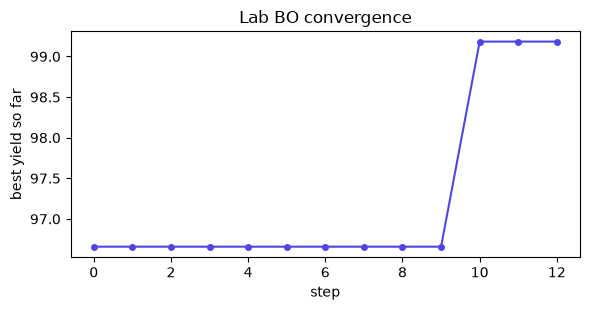

In [6]:
import matplotlib.pyplot as plt
from abbot.analysis import convergence

ys = convergence(result.history, spec)
plt.figure(figsize=(6, 3.2))
plt.plot(range(len(ys)), ys, "-o", color="#4f46e5", ms=4)
plt.xlabel("step"); plt.ylabel("best yield so far"); plt.title("Lab BO convergence")
plt.tight_layout(); plt.show()

### Categorical / discrete variables
abbot's design space is **type-polymorphic**: an `EnumeratedDomain` holds a finite
set of allowed values (a catalyst choice, a discrete grid). For an *all-enumerated*
space abbot automatically uses the discrete optimizer, which enumerates the
candidate set rather than coercing it to a float range — the call is unchanged:

```python
from abbot import EnumeratedDomain

spec = ProblemSpec(
    domain=[EnumeratedDomain(name="catalyst", values=[0.0, 1.0, 2.0, 3.0])],
    outputs=[OutputSpec(name="yield", direction="MAXIMIZE")],
)
result = run_campaign(spec, experiment, n_shots=8)
```

*(Mixed continuous **and** enumerated spaces in one problem need
`optimize_acqf_mixed`, which is a deferred extension point — abbot raises a clear
error rather than silently relaxing the discrete axis.)*

**What this showed:** a non-expert described continuous knobs and a single
objective; abbot fit a surrogate, proposed experiments, and recovered the best
setting — no ML expertise required in the loop.